# Credit Risk Analysis & Prediction

**Business question:** Can historical customer and credit information help estimate bad credit risk, and which recorded factors are associated with higher risk?

The outcome here is whether a historical credit contract was complied with. It is a proxy for credit risk, not a verified default date or loss amount. This is an exploratory portfolio study, not a lending policy.

## Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (8, 5), "axes.spines.top": False,
                     "axes.spines.right": False})
project_root = Path.cwd().parent
images_dir = project_root / "images"
portfolio_dir = project_root / "portfolio"
images_dir.mkdir(exist_ok=True)
portfolio_dir.mkdir(exist_ok=True)

## Load Data

Source: [UCI South German Credit](https://archive.ics.uci.edu/dataset/573/south+german+credit+update), licensed CC BY 4.0. The raw file and its original code table are included under `data/raw/`. The sample contains credit records from 1973–1975. The source states that bad credits were deliberately oversampled, so the sample rate is not a population default rate.

In [2]:
raw = pd.read_csv(project_root / "data/raw/SouthGermanCredit.asc", sep=r"\s+")
column_names = {
    "laufkont": "checking_status", "laufzeit": "duration_months",
    "moral": "credit_history", "verw": "purpose", "hoehe": "credit_amount_dm",
    "sparkont": "savings", "beszeit": "employment_duration",
    "rate": "installment_rate", "famges": "personal_status_sex",
    "buerge": "other_debtors", "wohnzeit": "residence_duration",
    "verm": "property", "alter": "age_years",
    "weitkred": "other_installment_plans", "wohn": "housing",
    "bishkred": "number_credits", "beruf": "job",
    "pers": "people_liable", "telef": "telephone",
    "gastarb": "foreign_worker", "kredit": "credit_risk"
}
df = raw.rename(columns=column_names).copy()
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
df.head()

Rows: 1,000; columns: 21


,checking_status,duration_months,credit_history,purpose,credit_amount_dm,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age_years,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


## Data Understanding

The three measured numerical fields are credit duration (months), credit amount (DM, transformed in the source), and age (years). The other 17 predictors are coded categories, including ordered bands and binary flags; their codes are not continuous measurements. `credit_risk` is `0 = bad` and `1 = good` in the source. For evaluation, `bad_credit = 1` is the positive class. The dataset has no income variable.

In [3]:
numeric_features = ["duration_months", "credit_amount_dm", "age_years"]
categorical_features = [c for c in df.columns if c not in numeric_features + ["credit_risk"]]
print("Data types:")
print(df.dtypes.value_counts())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Original target counts:")
print(df.credit_risk.value_counts().sort_index())
print("Numerical ranges:")
display(df[numeric_features].describe().round(1))
print("99th percentiles:", dict(zip(numeric_features, np.percentile(df[numeric_features], 99, axis=0).round(1))))

Data types:
int64    21
Name: count, dtype: int64
Missing values: 0
Duplicate rows: 0
Original target counts:
credit_risk
0    300
1    700
Name: count, dtype: int64
Numerical ranges:


,duration_months,credit_amount_dm,age_years
count,1000.0,1000.0,1000.0
mean,20.9,3271.2,35.5
std,12.1,2822.8,11.4
min,4.0,250.0,19.0
25%,12.0,1365.5,27.0
50%,18.0,2319.5,33.0
75%,24.0,3972.2,42.0
max,72.0,18424.0,75.0


99th percentiles: {'duration_months': np.float64(60.0), 'credit_amount_dm': np.float64(14180.4), 'age_years': np.float64(67.0)}


## Data Cleaning

The source has no missing values or duplicate rows. Category codes are checked against the accompanying code table before being converted to readable labels. No observations are removed: large credit amounts and long durations are plausible loans, and automatic outlier trimming would discard potentially informative cases. Median and most frequent imputers are still fitted within training folds so the workflow handles future missing inputs without using test data.

In [4]:
category_labels = {
    "checking_status": {1: "No account", 2: "Below 0 DM", 3: "0–200 DM", 4: "200+ DM"},
    "credit_history": {0: "Past delay", 1: "Critical/other credit", 2: "No/prior paid", 3: "Current paid", 4: "All paid"},
    "purpose": {0: "Other", 1: "New car", 2: "Used car", 3: "Furniture", 4: "Radio/TV", 5: "Appliances", 6: "Repairs", 7: "Education", 8: "Vacation", 9: "Retraining", 10: "Business"},
    "savings": {1: "Unknown/no account", 2: "Below 100 DM", 3: "100–500 DM", 4: "500–1000 DM", 5: "1000+ DM"},
    "employment_duration": {1: "Unemployed", 2: "Below 1 year", 3: "1–4 years", 4: "4–7 years", 5: "7+ years"},
    "installment_rate": {1: "35%+", 2: "25–35%", 3: "20–25%", 4: "Below 20%"},
    "personal_status_sex": {1: "Male separated", 2: "Female non-single/male single", 3: "Male married/widowed", 4: "Female single"},
    "other_debtors": {1: "None", 2: "Co-applicant", 3: "Guarantor"},
    "residence_duration": {1: "Below 1 year", 2: "1–4 years", 3: "4–7 years", 4: "7+ years"},
    "property": {1: "Unknown/none", 2: "Car/other", 3: "Savings/insurance", 4: "Real estate"},
    "other_installment_plans": {1: "Bank", 2: "Stores", 3: "None"},
    "housing": {1: "Free", 2: "Rent", 3: "Own"},
    "number_credits": {1: "1", 2: "2–3", 3: "4–5", 4: "6+"},
    "job": {1: "Unemployed/nonresident", 2: "Unskilled", 3: "Skilled", 4: "Manager/self-employed"},
    "people_liable": {1: "3+", 2: "0–2"},
    "telephone": {1: "No", 2: "Yes"},
    "foreign_worker": {1: "Yes", 2: "No"}
}
for column, labels in category_labels.items():
    unexpected = set(df[column].dropna().unique()) - set(labels)
    if unexpected:
        raise ValueError(f"Unexpected codes in {column}: {unexpected}")
    df[column] = df[column].map(labels).astype("category")

if set(df.credit_risk.unique()) != {0, 1}:
    raise ValueError("Unexpected target values")
df["bad_credit"] = (df.credit_risk == 0).astype(int)
df = df.drop(columns="credit_risk")
print("Missing values after mapping:", int(df.isna().sum().sum()))
print("Bad credit rate:", f"{df.bad_credit.mean():.1%}")

Missing values after mapping: 0
Bad credit rate: 30.0%


## Exploratory Data Analysis

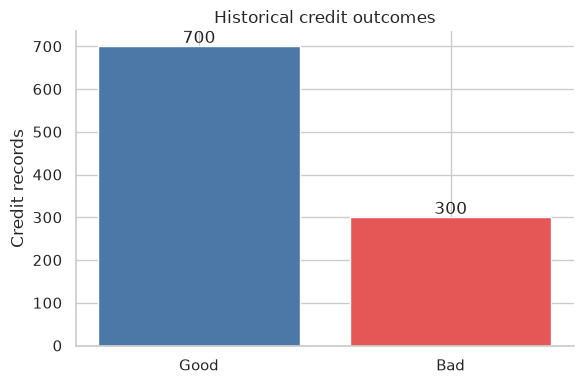

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = df.bad_credit.value_counts().sort_index()
ax.bar(["Good", "Bad"], counts.values, color=["#4C78A8", "#E45756"])
for i, value in enumerate(counts.values):
    ax.text(i, value + 8, f"{value:,}", ha="center")
ax.set(ylabel="Credit records", title="Historical credit outcomes")
fig.tight_layout()
fig.savefig(images_dir / "credit_outcomes.png", dpi=170)
plt.show()

**Observation:** 300 of 1,000 records have a bad outcome. Because bad outcomes were oversampled, 30% should not be used as an expected rate for new applicants.

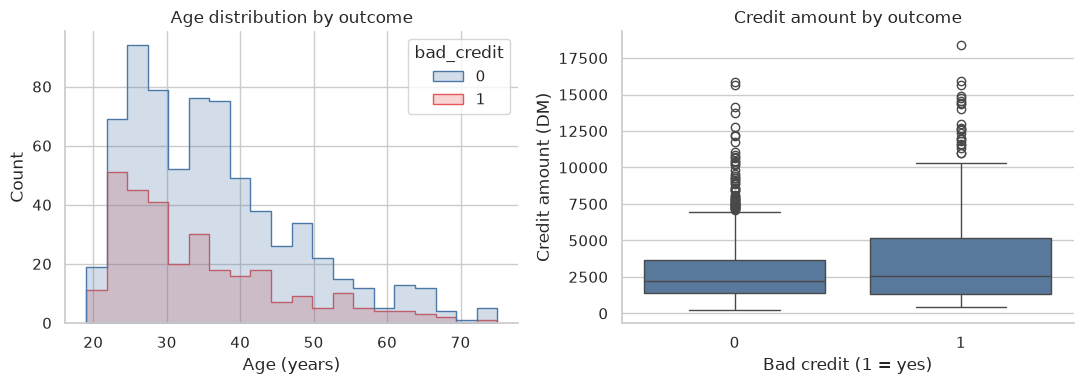

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="age_years", hue="bad_credit", bins=20, element="step", ax=axes[0], palette={0: "#4C78A8", 1: "#E45756"})
axes[0].set(title="Age distribution by outcome", xlabel="Age (years)")
sns.boxplot(data=df, x="bad_credit", y="credit_amount_dm", ax=axes[1], color="#4C78A8")
axes[1].set(title="Credit amount by outcome", xlabel="Bad credit (1 = yes)", ylabel="Credit amount (DM)")
fig.tight_layout()
plt.show()

**Observation:** Amounts are right skewed and include high values; the source says amounts were transformed, so DM values should be interpreted cautiously. Age and amount distributions overlap substantially between outcomes.

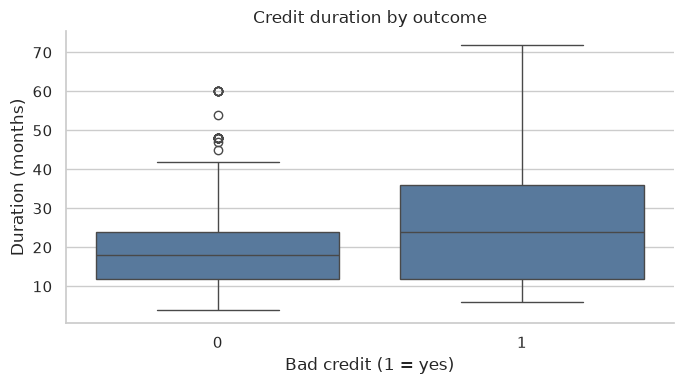

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="bad_credit", y="duration_months", ax=ax, color="#4C78A8")
ax.set(title="Credit duration by outcome", xlabel="Bad credit (1 = yes)", ylabel="Duration (months)")
fig.tight_layout()
plt.show()

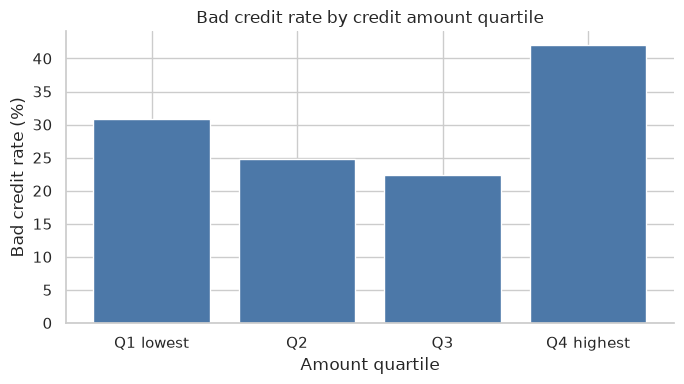

In [8]:
df["amount_band"] = pd.qcut(df.credit_amount_dm, q=4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
fig, ax = plt.subplots(figsize=(7, 4))
amount_risk = df.groupby("amount_band", observed=True).bad_credit.agg(["mean", "size"])
ax.bar(amount_risk.index.astype(str), amount_risk["mean"] * 100, color="#4C78A8")
ax.set(title="Bad credit rate by credit amount quartile", ylabel="Bad credit rate (%)", xlabel="Amount quartile")
fig.tight_layout()
fig.savefig(images_dir / "amount_risk.png", dpi=170)
plt.show()
df = df.drop(columns="amount_band")

**Observation:** These are within-sample rates, not causal effects. Quartiles have similar group sizes and help compare risk across credit amounts without treating extreme loans as errors.

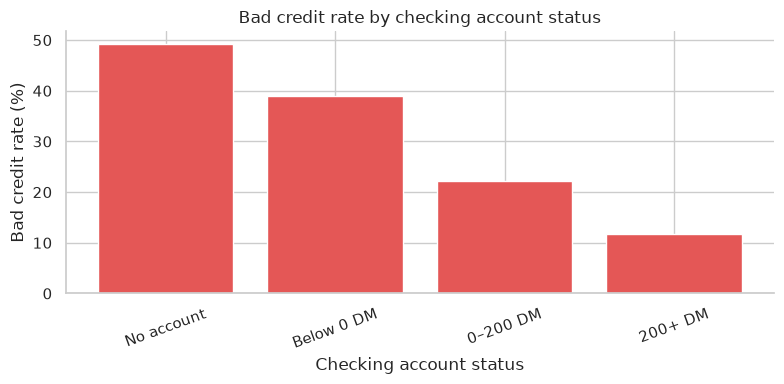

,mean,size
checking_status,,
No account,0.493,274
Below 0 DM,0.390,269
0–200 DM,0.222,63
200+ DM,0.117,394


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
status_risk = df.groupby("checking_status", observed=True).bad_credit.agg(["mean", "size"]).sort_values("mean", ascending=False)
ax.bar(status_risk.index.astype(str), status_risk["mean"] * 100, color="#E45756")
ax.set(title="Bad credit rate by checking account status", ylabel="Bad credit rate (%)", xlabel="Checking account status")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(images_dir / "checking_risk.png", dpi=170)
plt.show()
display(status_risk.round(3))

**Observation:** Checking status separates outcomes noticeably in this sample. The rates describe groups in historical data and are not a reason to make an automatic individual decision.

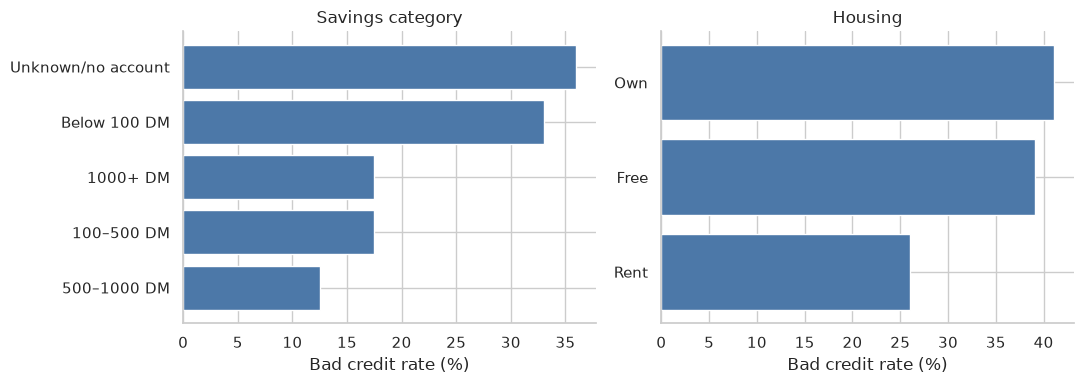

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column, title in [(axes[0], "savings", "Savings category"), (axes[1], "housing", "Housing")]:
    rates = df.groupby(column, observed=True).bad_credit.agg(["mean", "size"]).sort_values("mean", ascending=False)
    ax.barh(rates.index.astype(str), rates["mean"] * 100, color="#4C78A8")
    ax.invert_yaxis()
    ax.set(title=title, xlabel="Bad credit rate (%)")
fig.tight_layout()
plt.show()

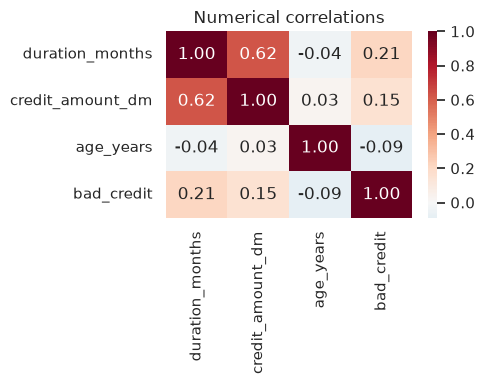

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(df[numeric_features + ["bad_credit"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set(title="Numerical correlations")
fig.tight_layout()
plt.show()

**Observation:** Correlations summarize linear relationships among measured fields. They do not capture category effects or establish causation.

## Data Preparation

The 20 source predictors are used; the target is excluded. A stratified 80/20 split preserves the sample class mix. Imputation, one-hot encoding, and scaling are fitted on training data through each pipeline. Scaled numerical fields help logistic regression; the same preprocessing keeps model comparisons straightforward.

In [12]:
X = df.drop(columns="bad_credit")
y = df.bad_credit
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
preprocess = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])
print("Training rows:", len(X_train), "Test rows:", len(X_test))
print("Bad outcomes in test set:", int(y_test.sum()))

Training rows: 800 Test rows: 200
Bad outcomes in test set: 60


## Model Training

Three common classifiers are trained with default or simple settings. The test set is held out until evaluation; there is no tuning on test results.

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=15, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)
}
fitted_models = {}
for name, estimator in models.items():
    pipeline = Pipeline([("preprocess", preprocess), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

## Model Evaluation

The positive class is bad credit. **Recall** measures how many bad outcomes are identified; missed bad outcomes may be costly. **Precision** measures how often a flagged case really had a bad outcome; low precision can create unnecessary reviews. ROC-AUC summarizes ranking across thresholds. Accuracy alone can hide poor detection when classes differ in size. These metrics use a 0.5 classification threshold and one untouched test set.

In [14]:
results = []
for name, pipeline in fitted_models.items():
    predicted = pipeline.predict(X_test)
    probability = pipeline.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted),
        "F1": f1_score(y_test, predicted),
        "ROC-AUC": roc_auc_score(y_test, probability)
    })
results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results_df.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.770,0.769,0.333,0.465,0.755
Logistic Regression,0.740,0.591,0.433,0.500,0.742
Decision Tree,0.735,0.640,0.267,0.376,0.689


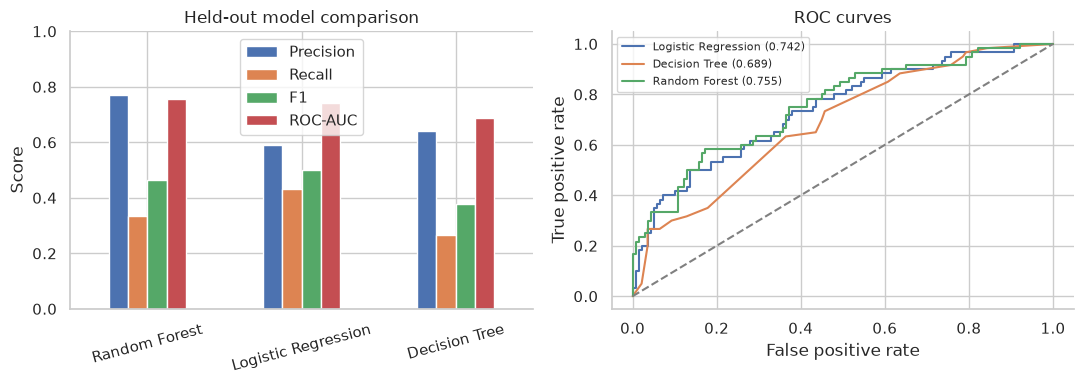

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
results_df[["Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(ax=axes[0], ylim=(0, 1), rot=15)
axes[0].set(title="Held-out model comparison", ylabel="Score", xlabel="")
for name, pipeline in fitted_models.items():
    fpr, tpr, _ = roc_curve(y_test, pipeline.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(images_dir / "model_comparison.png", dpi=170)
plt.show()

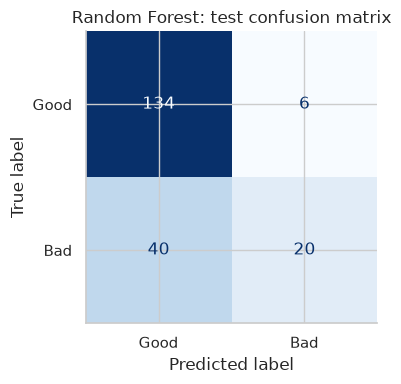

Best ROC-AUC: Random Forest
Confusion matrix [good, bad]:
[[134   6]
 [ 40  20]]


In [16]:
best_name = results_df.index[0]
best_model = fitted_models[best_name]
best_prediction = best_model.predict(X_test)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, best_prediction, display_labels=["Good", "Bad"], cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"{best_name}: test confusion matrix")
fig.tight_layout()
fig.savefig(images_dir / "confusion_matrix.png", dpi=170)
plt.show()
print("Best ROC-AUC:", best_name)
print("Confusion matrix [good, bad]:")
print(confusion_matrix(y_test, best_prediction))

## Model Interpretation

Logistic regression coefficients show associations with predicted bad-credit odds after one-hot encoding and scaling. They depend on the other included features and are not causal effects. Coefficients for individual category levels are relative to the model's encoded representation; use them as directional clues, not standalone rules.

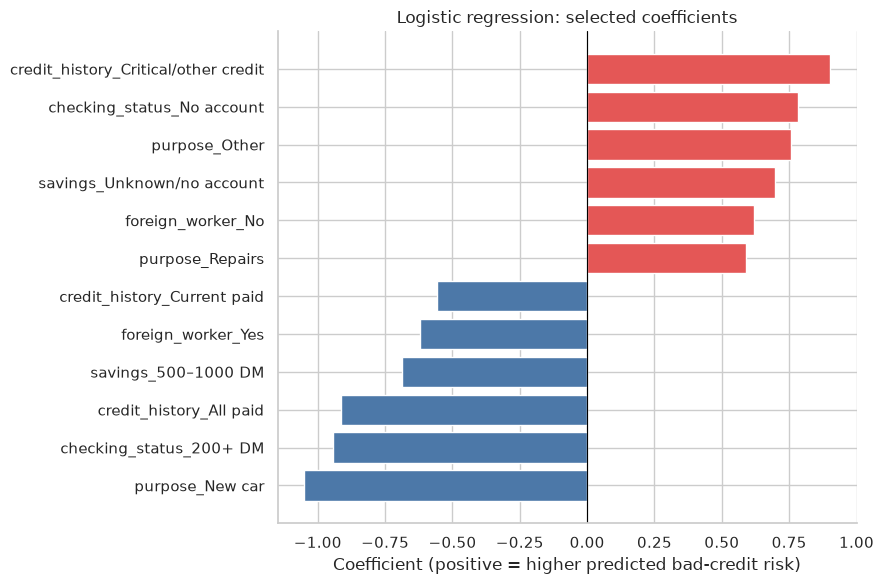

categorical__purpose_New car                        -1.052
categorical__checking_status_200+ DM                -0.944
categorical__credit_history_All paid                -0.915
categorical__savings_500–1000 DM                    -0.688
categorical__foreign_worker_Yes                     -0.620
categorical__credit_history_Current paid            -0.556
categorical__purpose_Repairs                         0.589
categorical__foreign_worker_No                       0.621
categorical__savings_Unknown/no account              0.697
categorical__purpose_Other                           0.757
categorical__checking_status_No account              0.781
categorical__credit_history_Critical/other credit    0.903
dtype: float64

In [17]:
logistic = fitted_models["Logistic Regression"]
feature_names = logistic.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(logistic.named_steps["model"].coef_[0], index=feature_names)
key_coefficients = pd.concat([coefficients.nsmallest(6), coefficients.nlargest(6)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#4C78A8" if value < 0 else "#E45756" for value in key_coefficients]
ax.barh(key_coefficients.index.str.replace("categorical__", "").str.replace("numeric__", ""), key_coefficients.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Logistic regression: selected coefficients", xlabel="Coefficient (positive = higher predicted bad-credit risk)")
fig.tight_layout()
fig.savefig(images_dir / "feature_coefficients.png", dpi=170)
plt.show()
display(key_coefficients.round(3))

## Business Insights

The following statements are filled from the executed analysis so their figures match the tables and charts above.

In [18]:
def rate_for(column, category):
    return df.loc[df[column] == category, "bad_credit"].mean()

low_status = rate_for("checking_status", "Below 0 DM")
high_status = rate_for("checking_status", "200+ DM")
long_duration = df.loc[df.duration_months > 24, "bad_credit"].mean()
short_duration = df.loc[df.duration_months <= 24, "bad_credit"].mean()
large_amount = df.loc[df.credit_amount_dm > df.credit_amount_dm.median(), "bad_credit"].mean()
small_amount = df.loc[df.credit_amount_dm <= df.credit_amount_dm.median(), "bad_credit"].mean()
insights = [
    f"Checking accounts below 0 DM had {low_status:.1%} bad outcomes, versus {high_status:.1%} for accounts at 200+ DM.",
    f"Credits longer than 24 months had {long_duration:.1%} bad outcomes, versus {short_duration:.1%} for shorter credits.",
    f"Above-median credit amounts had {large_amount:.1%} bad outcomes, versus {small_amount:.1%} for the lower half.",
    f"The sample has {y.mean():.1%} bad outcomes, but this rate reflects deliberate oversampling.",
    f"{best_name} has the highest test ROC-AUC ({results_df.loc[best_name, 'ROC-AUC']:.3f}) among these three models."
]
for item in insights:
    print("•", item)
print("Predictive scores should support risk assessment and human review, not automatically determine lending decisions.")

• Checking accounts below 0 DM had 39.0% bad outcomes, versus 11.7% for accounts at 200+ DM.
• Credits longer than 24 months had 44.3% bad outcomes, versus 25.7% for shorter credits.
• Above-median credit amounts had 32.2% bad outcomes, versus 27.8% for the lower half.
• The sample has 30.0% bad outcomes, but this rate reflects deliberate oversampling.
• Random Forest has the highest test ROC-AUC (0.755) among these three models.
Predictive scores should support risk assessment and human review, not automatically determine lending decisions.


## Conclusion

The historical features show useful associations with bad credit outcomes, and the held-out comparison provides a modest benchmark. The dataset is small, old, and deliberately rebalanced, with no income field or modern lending context. A real deployment would need current representative data, calibration, fairness review, and an explicit decision process.

## Portfolio Figures

These summaries use the same cleaned data and held-out predictions shown above.

In [19]:
fig = plt.figure(figsize=(13, 7), facecolor="white")
fig.suptitle("Credit Risk Analysis & Prediction", fontsize=20, fontweight="bold", x=0.06, ha="left")
fig.text(0.06, 0.89, "Can historical credit information help estimate bad-credit risk?", fontsize=12)
axes = fig.subplots(1, 2, gridspec_kw={"left": 0.07, "right": 0.96, "bottom": 0.14, "top": 0.78, "wspace": 0.3})
axes[0].bar(["Good", "Bad"], counts.values, color=["#4C78A8", "#E45756"])
axes[0].set(title="Historical outcomes", ylabel="Records")
axes[1].bar(status_risk.index.astype(str), status_risk["mean"] * 100, color="#E45756")
axes[1].set(title="Bad outcome rate by checking status", ylabel="Rate (%)")
axes[1].tick_params(axis="x", rotation=20)
fig.text(0.07, 0.05, "UCI South German Credit · 1,000 records · historical, oversampled sample", fontsize=10, color="#555555")
fig.savefig(portfolio_dir / "credit_risk_overview.png", dpi=170, facecolor="white")
plt.close(fig)

fig = plt.figure(figsize=(13, 7), facecolor="white")
fig.suptitle("Model Results", fontsize=20, fontweight="bold", x=0.06, ha="left")
fig.text(0.06, 0.89, "Held-out test set · 200 records · positive class: bad credit", fontsize=12)
axes = fig.subplots(1, 2, gridspec_kw={"left": 0.08, "right": 0.97, "bottom": 0.18, "top": 0.79, "wspace": 0.32})
results_df[["Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(ax=axes[0], ylim=(0, 1), rot=15)
axes[0].set(title="Model comparison", ylabel="Score", xlabel="")
axes[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(y_test, best_prediction, display_labels=["Good", "Bad"], cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title(f"{best_name} confusion matrix")
fig.text(0.08, 0.04, f"Best ROC-AUC: {best_name} ({results_df.loc[best_name, 'ROC-AUC']:.3f})", fontsize=11)
fig.savefig(portfolio_dir / "model_results.png", dpi=170, facecolor="white")
plt.close(fig)

fig = plt.figure(figsize=(13, 7), facecolor="white")
fig.suptitle("Key Insights", fontsize=20, fontweight="bold", x=0.06, ha="left")
ax = fig.add_axes([0.24, 0.16, 0.29, 0.68])
short_names = key_coefficients.index.str.replace("categorical__", "").str.replace("numeric__", "")
short_names = [name.replace("checking_status_", "Checking: ").replace("credit_history_", "History: ").replace("foreign_worker_", "Foreign worker: ").replace("savings_", "Savings: ").replace("purpose_", "Purpose: ") for name in short_names]
ax.barh(short_names, key_coefficients.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Logistic regression associations", xlabel="Coefficient: positive means higher risk")
fig.text(0.58, 0.75, "Observed in this sample", fontsize=14, fontweight="bold")
for i, item in enumerate(insights[:4]):
    import textwrap
    fig.text(0.58, 0.68 - i * 0.15, textwrap.fill("• " + item, width=53), fontsize=10.5, va="top")
fig.text(0.58, 0.06, "Associations are not causal; use scores to support review.", fontsize=10, color="#555555")
fig.savefig(portfolio_dir / "key_insights.png", dpi=170, facecolor="white")
plt.close(fig)
print("Saved three portfolio figures.")

Saved three portfolio figures.
